# look

clade cards and umap paths for a run, side by side across methods. the clades are picked once and saved to `clades.csv`, so every figure shows the same ones: a seeded draw stratified by embryo stage, plus the 3 with the most germ crossing. needs the couplings first:

```
python evaluate.py -m hydra/launcher=lids run_name=cand1 fill=sampler,posterior_mean,mean_pool,random_descendant
python evaluate.py -m hydra/launcher=lids run_name=cand1 scramble=true fill=sampler
```

figures go to `<run>/look/`.

In [1]:
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from hydra.utils import instantiate
from omegaconf import OmegaConf

from li.data.tree import scramble
from li.eval.nodes import clade, clades, crossing, label
from li.plot import tree as pt, umap as pu

run = "../runs/cand1"
methods = ["sampler", "posterior_mean", "mean_pool", "random_descendant", "sampler_scrambled"]
data = instantiate(OmegaConf.load("../config/data/mouse.yaml"), device="cuda", _convert_="all")
rng = np.random.default_rng(0)  # the permutation evaluate.py used
scrambled = {n: scramble(t, rng) for n, t in data.trees.items()}

In [2]:
path = f"{run}/clades.csv"
if not os.path.exists(path):
    clades(data, label(pd.read_parquet(f"{run}/coupling_sampler.parquet"), data.labels)).to_csv(path, index=False)
cl = pd.read_csv(path)
cl

,tree,stage,root,node,n_leaves,n_edges,crossing,why
0,E9.5-R3-C1,9.5,151772,UVTsJFHL,110,182.0,0.000000,random
1,E8.5-R3-C1,8.5,31839,WnmC95iY,32,42.0,0.166667,random
2,E10.0-R1-C5,10.0,6833,2PduYKSb,45,87.0,0.000000,random
3,E9.0-R2-C1,9.0,12755,i7WgQsmz,39,67.0,0.134328,random
4,E8.0-R1-C1,8.0,2404,UydVXVtr,33,16.0,0.375000,random
5,E9.5-R3-C2,9.5,42292,vJjnSGXj,30,74.0,0.202703,random
6,E10.0-R1-C3,10.0,69285,xyKtRIqP,59,147.0,0.000000,random
7,E9.0-R3-C1,9.0,44218,Z9ekQINV,79,108.0,0.046296,random
8,E9.5-R3-C2,9.5,60350,fdlphIvK,30,41.0,0.634146,worst
9,E9.5-R3-C1,9.5,27054,20JPXIOE,37,51.0,0.627451,worst


In [3]:
keep = [("tree", "in", list(cl.tree.unique()))]
coup = {m: label(pd.read_parquet(f"{run}/coupling_{m}.parquet", filters=keep), data.labels) for m in methods}

how to read a card: time runs along x, one row per leaf, leaves coloured by observed type. edges take the child's modal predicted type, faded where samples disagree. the ticks stepping back from each node are the individual samples. a red x is an edge that crosses germ layers (opacity = share of samples). in the umap row, each sample's ancestors are joined parent to child and coloured by time.

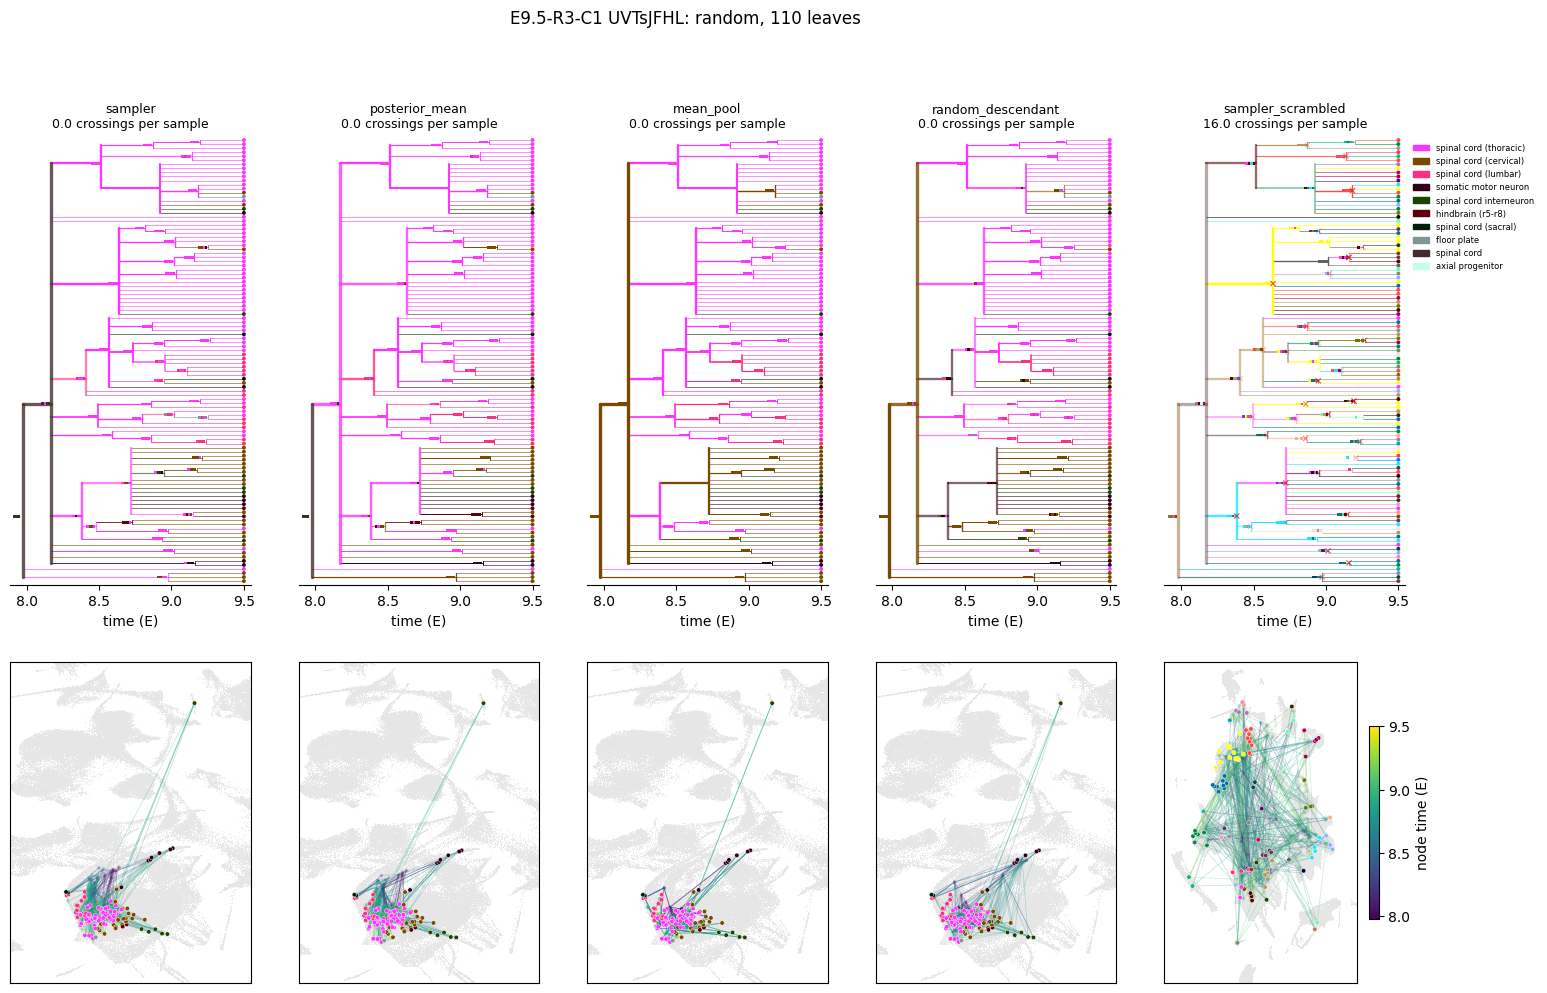

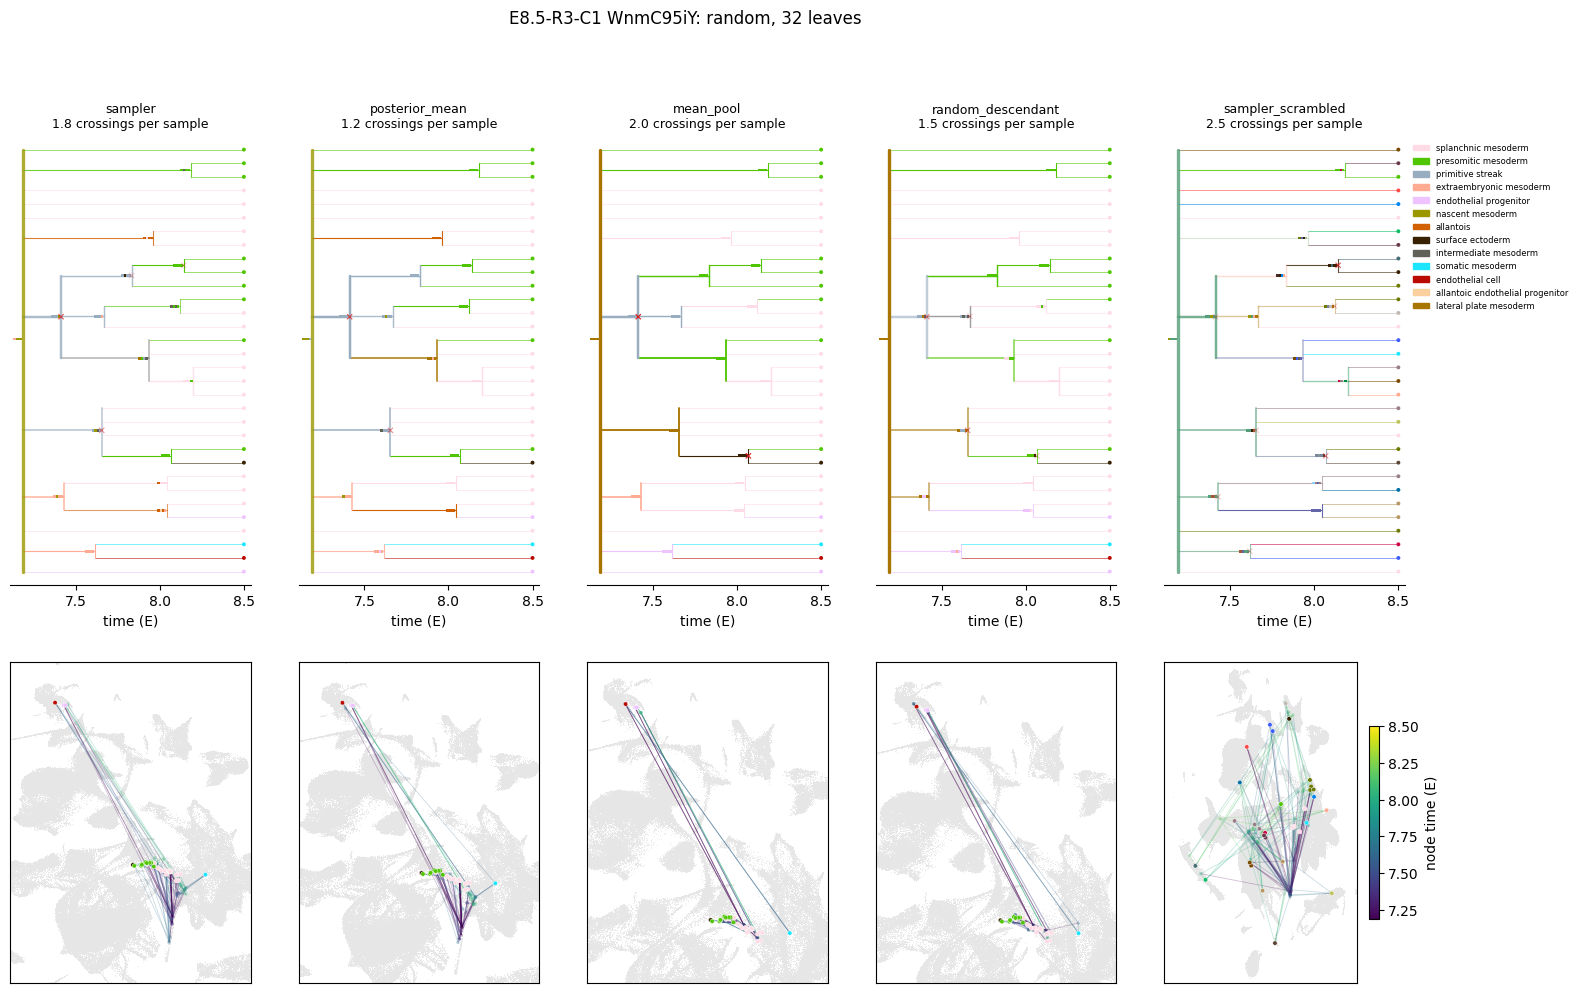

In [4]:
os.makedirs(f"{run}/look", exist_ok=True)
for i, c in cl.iterrows():
    fig, ax = plt.subplots(2, len(methods), figsize=(3.6 * len(methods), 11), gridspec_kw=dict(height_ratios=[1.4, 1]))
    for k, m in enumerate(methods):
        t = (scrambled if m.endswith("scrambled") else data.trees)[c.tree]
        r = np.flatnonzero(t.nodes == c.node)[0]
        lab = clade(data, coup[m], t, r)
        x = crossing(data, coup[m], t, r)
        pt.card(ax[0, k], t, r, lab, data.colors, x)
        ax[0, k].set_title(f"{m}\n{x.sum():.1f} crossings per sample", fontsize=9)
        pu.atlas(ax[1, k], data.umap)
        norm = pu.path(ax[1, k], data.umap, t, r, clade(data, coup[m], t, r, "cell"), data.colors, lab[t.leaf[r:t.end[r]], 0])
    pt.key(ax[0, -1], clade(data, coup[methods[0]], data.trees[c.tree], r), data.colors,
           loc="upper left", bbox_to_anchor=(1, 1), fontsize=6)
    fig.colorbar(plt.cm.ScalarMappable(norm, "viridis"), ax=ax[1, -1], label="node time (E)", shrink=0.6)
    fig.suptitle(f"{c.tree} {c.node}: {c.why}, {c.n_leaves} leaves", y=0.995)
    fig.savefig(f"{run}/look/{i:02d}_{c.tree}_{c.node}.png", dpi=110, bbox_inches="tight")
    plt.show() if i < 2 else plt.close(fig)